In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

In [26]:
def create_blobs(n_samples=1000, random_state=42):
    rng = np.random.default_rng(random_state)

    # Centers approximately matching the figure
    centers = np.array([
        [-2.8, 2.8],   # top-left
        [-2.8, 1.8],   # middle-left
        [-2.8, 1.3],   # bottom-left
        [-1.5, 2.3],   # middle
        [ 0.2, 2.3],   # right
    ])

    # Standard deviations for each blob
    stds = np.array([
        [0.12, 0.12],
        [0.13, 0.13],
        [0.13, 0.13],
        [0.45, 0.30],
        [0.50, 0.45],
    ])

    # Number of points per blob
    n_per_blob = n_samples // len(centers)

    X = np.vstack([
        rng.normal(
            loc=center,
            scale=std,
            size=(n_per_blob, 2)
        )
        for center, std in zip(centers, stds)
    ])

    return X

In [27]:
X = create_blobs()

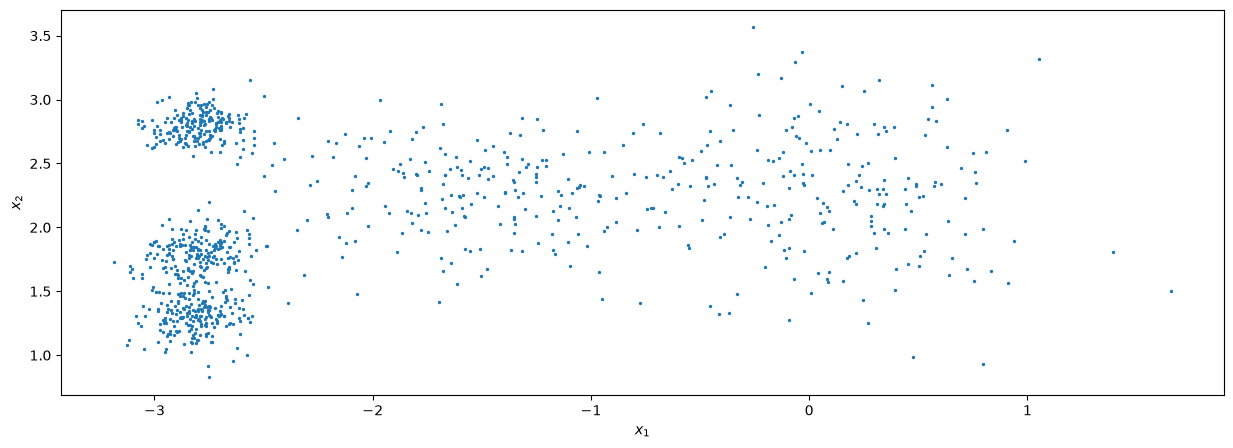

In [28]:
plt.figure(figsize=(15,5))
plt.scatter(X[:, 0], X[:, 1], s=2)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()

#### Training the K means clustering

In [29]:
k = 5
kmeans = KMeans(n_clusters=k)
y_pred = kmeans.fit_predict(X)

In [30]:
y_pred is kmeans.labels_

True

In [31]:
kmeans.cluster_centers_

array([[-2.75954326,  2.78271422],
       [ 0.11565083,  2.27657793],
       [-2.77093809,  1.81349321],
       [-2.80720359,  1.30580134],
       [-1.40338316,  2.27161041]])

In [32]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])

In [33]:
kmeans.transform(X_new)

array([[2.86840034, 0.29978404, 2.77720771, 2.89176482, 1.42942524],
       [5.81248484, 2.89757924, 5.77395109, 5.84854899, 4.41175197],
       [0.32408727, 3.19853398, 1.20841538, 1.7051333 , 1.75491787],
       [0.37114253, 3.12365131, 0.72371329, 1.20966148, 1.61286923]])